In [1]:
import os

# Byter arbetskatalog från notebooks till projektroten, så att Python kan hitta både src/ och data/
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

# Kontrollerar vilken mapp Python arbetar från
print(os.getcwd())

c:\Users\Speldator\Desktop\data-science-group-project


In [2]:
from src.data_split import load_cleaned_data, get_splits

# Läser in den rensade datan från data/processed/
df = load_cleaned_data()

# Kontrollerar datasetets storlek
print("Antal bokningar:", df.shape[0])
print("Antal kolumner:", df.shape[1])

# Visar fem slumpmässiga bokningar
df.sample(5, random_state=42).T

2026-10-15 11:22:03 [INFO] src.data_split: Läser in städad data från data\processed\hotel_bookings_cleaned.csv
Antal bokningar: 110428
Antal kolumner: 34


,2448,48466,13766,20972,80486
hotel,Resort Hotel,City Hotel,Resort Hotel,Resort Hotel,City Hotel
is_canceled,1,1,0,0,0
lead_time,112,179,73,21,82
arrival_date_year,2016,2016,2015,2016,2016
arrival_date_month,February,July,September,June,May
arrival_date_week_number,7,27,40,23,21
arrival_date_day_of_month,12,1,28,2,17
stays_in_weekend_nights,0,0,1,0,0
stays_in_week_nights,2,2,1,1,3
adults,2,2,2,1,3


In [3]:
# Delar upp den rensade datan kronologiskt
splits = get_splits(df)

# Hämtar träningsdata och valideringsdata
train = splits["train_val"]
val = splits["val"]

# Kontrollerar antal rader och kolumner
print("Train:", train.shape)
print("Validation:", val.shape)

2026-10-15 11:22:04 [INFO] src.data_split: Split vid 2016-07-01: 40414 träning (avbokade 0.308), 11643 utvärdering (avbokade 0.353)
2026-10-15 11:22:04 [INFO] src.data_split: Split vid 2016-10-01: 55393 träning (avbokade 0.321), 14879 utvärdering (avbokade 0.396)
Train: (40414, 34)
Validation: (11643, 34)


In [4]:
from src.preprocessing import split_features_target

# Separera features (X) och facit (y) för träningsdatan
X_train, y_train = split_features_target(train)

# Gör samma sak för valideringsdatan
X_val, y_val = split_features_target(val)

# Kontrollera dimensionerna
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

X_train: (40414, 13)
y_train: (40414,)
X_val: (11643, 13)
y_val: (11643,)


In [5]:
from src.preprocessing import build_preprocessor

# Skapar preprocessorn med gruppens gemensamma inställningar
preprocessor = build_preprocessor()

# Lär sig medelvärden, standardavvikelser och kategorier från träningsdatan och omvandlar sedan denna
X_train_processed = preprocessor.fit_transform(X_train)

# Omvandlar valideringsdatan med samma inställningar
# Ingen ny fit() görs, vilket förhindrar dataläckage
X_val_processed = preprocessor.transform(X_val)

# Kontrollerar dimensionerna efter preprocessing
print("Train:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)

Train: (40414, 121)
Validation: (11643, 121)


In [6]:
from src.logistic_regression import train_logistic_regression

# Tränar Logistic Regression på den förbehandlade träningsdatan
model = train_logistic_regression(
    X_train_processed,
    y_train
)

# Bekräftar att modellen har tränats
print("Logistic Regression är tränad!")

Logistic Regression är tränad!


In [7]:
from src.prediction import predict_probabilities

# Beräknar sannolikheten för avbokning (klass 1)
# för varje bokning i valideringsdatan
probabilities = predict_probabilities(
    model,
    X_val_processed
)

# Visar de första 10 sannolikheterna
print(probabilities[:10])

[0.14699224 0.13062209 0.1880799  0.10742402 0.15524815 0.11204995
 0.10955545 0.29144927 0.16983085 0.10327039]


In [8]:
from src.evaluation import flag_top_share

# Flagga de 20 % av bokningarna som har högst
# förutsagd sannolikhet att avbokas.
y_pred = flag_top_share(probabilities, share=0.20)

# Kontrollera hur många bokningar som flaggats.
print("Totalt antal bokningar:", len(y_pred))
print("Antal flaggade:", y_pred.sum())

Totalt antal bokningar: 11643
Antal flaggade: 2329


In [9]:
from src.evaluation import evaluate_top_share

# Utvärdera de 20 % av bokningarna med högst avbokningsrisk.
results = evaluate_top_share(
    y_true=y_val,
    scores=probabilities,
    share=0.20
)

# Visa antal bokningar och hur många som flaggades korrekt.
print("Totalt antal bokningar:", results["antal_bokningar"])
print("Antal flaggade:", results["antal_flaggade"])
print("Korrekt flaggade:", results["korrekt_flaggade"])

# Skriv ut Precision, Recall och F1-score i procent
for metric in ["precision", "recall", "f1_score"]:
    print(f"{metric.capitalize()}: {results[metric]:.2%}")

Totalt antal bokningar: 11643
Antal flaggade: 2329
Korrekt flaggade: 1434
Precision: 61.57%
Recall: 34.92%
F1_score: 44.56%


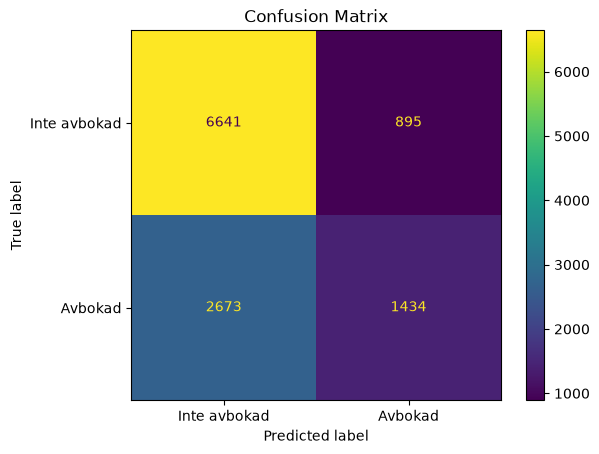

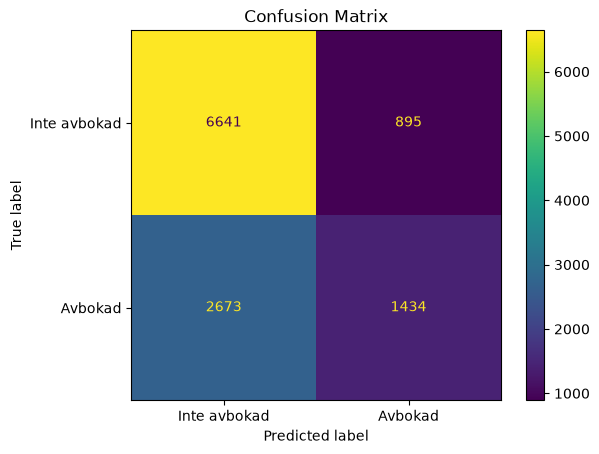

In [10]:
from src.evaluation import plot_confusion_matrix

# Visualiserar modellens förutsägelser mot facit
# y_val = verkliga utfall
# y_pred = de 20 % bokningar som har högst avbokningsrisk
plot_confusion_matrix(y_val, y_pred)

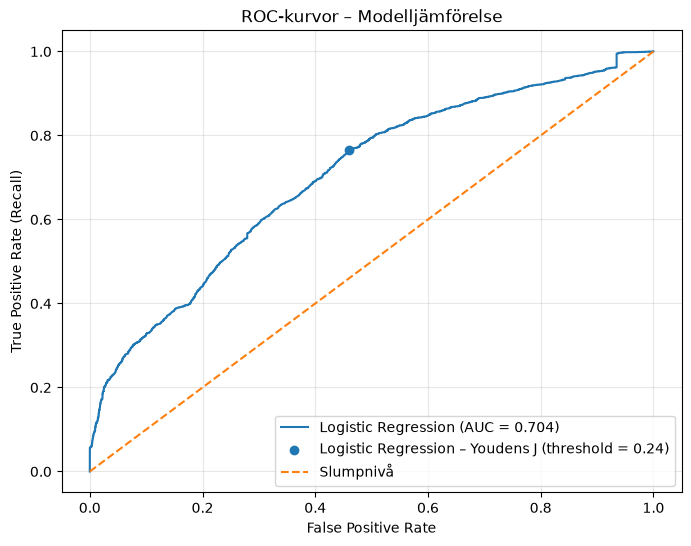

In [11]:
from src.evaluation import plot_roc_curve


# Skapar en dictionary med modellnamn och sannolikheter.
predictions = {
    "Logistic Regression": probabilities
}

# Ritar ROC-kurvan.
roc_results = plot_roc_curve(y_val, predictions)

In [12]:
# Utvärdera baseline på samma valideringsdata som Logistic Regression
baseline_results = evaluate_top_share(y_val, val["lead_time"])

# Jämför modellernas resultat
for metric in ["precision", "recall", "f1_score"]:
    print(f"{metric}: Baseline {baseline_results[metric]:.2%} | Logistic Regression {results[metric]:.2%}")

precision: Baseline 54.36% | Logistic Regression 61.57%
recall: Baseline 30.83% | Logistic Regression 34.92%
f1_score: Baseline 39.34% | Logistic Regression 44.56%
